# 02 · Rao-style hierarchical generative predictive coding: MNIST reconstruction

- Fully connected generative model; latent states inferred by iterative prediction-error minimisation.


In [1]:
import torch
import torch.nn.functional as F
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import time

torch.manual_seed(1234)
from archive.utils import get_device
DEVICE = get_device()
BATCH_SIZE, EPOCHS, T = 100, 25, 200
TAU, DT, LR = 20., 1., 0.001
ACTIVITY_PRIOR, WEIGHT_DECAY = 0.02, 1e-4
DIMS = (784, 256, 128, 64)
train_loader = DataLoader(MNIST('data', train=True, download=True, transform=ToTensor()), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(MNIST('data', train=False, download=True, transform=ToTensor()), batch_size=BATCH_SIZE, shuffle=False)
print('Device:', DEVICE)

Device: mps


In [2]:
class GenerativeHPC:
    def __init__(self, device):
        self.device = device
        # PyTorch [lower_dim, higher_dim]: upper latent predicts lower latent.
        self.W1 = torch.randn(DIMS[0], DIMS[1], device=device) * (2 / DIMS[1])**0.5
        self.W2 = torch.randn(DIMS[1], DIMS[2], device=device) * (2 / DIMS[2])**0.5
        self.W3 = torch.randn(DIMS[2], DIMS[3], device=device) * (2 / DIMS[3])**0.5
        self.weights = [self.W1, self.W2, self.W3]
        self.m = [torch.zeros_like(w) for w in self.weights]
        self.v = [torch.zeros_like(w) for w in self.weights]
        self.step = 0

    def activation(self, z):
        return z

    def derivative(self, z):
        return torch.ones_like(z)

    @torch.no_grad()
    def infer(self, x):
        # Feedforward initialization is an experimental modification.
        z1 = x @ self.W1
        z2 = self.activation(z1) @ self.W2
        z3 = self.activation(z2) @ self.W3
        for _ in range(T):
            a1, a2, a3 = self.activation(z1), self.activation(z2), self.activation(z3)
            e0 = x - a1 @ self.W1.T
            e1 = z1 - a2 @ self.W2.T
            e2 = z2 - a3 @ self.W3.T
            dz1 = (e0 @ self.W1) * self.derivative(z1) - e1 - ACTIVITY_PRIOR * z1.sign()
            dz2 = (e1 @ self.W2) * self.derivative(z2) - e2 - ACTIVITY_PRIOR * z2.sign()
            dz3 = (e2 @ self.W3) * self.derivative(z3) - ACTIVITY_PRIOR * z3.sign()
            z1 = z1 + DT / TAU * dz1
            z2 = z2 + DT / TAU * dz2
            z3 = z3 + DT / TAU * dz3
        a1, a2, a3 = self.activation(z1), self.activation(z2), self.activation(z3)
        recon = a1 @ self.W1.T
        e0, e1, e2 = x - recon, z1 - a2 @ self.W2.T, z2 - a3 @ self.W3.T
        energy = 0.5 * (e0.square().sum(1) + e1.square().sum(1) + e2.square().sum(1)).mean().item()
        return recon, (a1, a2, a3), (e0, e1, e2), energy

    @torch.no_grad()
    def train_batch(self, x):
        recon, acts, errors, energy = self.infer(x)
        # Locally formed negative gradients, no autograd across the hierarchy.
        gradients = [-(err.T @ act / x.shape[0]) + WEIGHT_DECAY * w for err, act, w in zip(errors, acts, self.weights)]
        self.step += 1
        for k, (w, g) in enumerate(zip(self.weights, gradients)):
            self.m[k] = 0.9 * self.m[k] + 0.1 * g
            self.v[k] = 0.999 * self.v[k] + 0.001 * g.square()
            w.addcdiv_(self.m[k] / (1 - 0.9**self.step), (self.v[k] / (1 - 0.999**self.step)).sqrt() + 1e-8, value=-LR)
        return energy

In [3]:
@torch.no_grad()
def evaluate(model, loader):
    total_mse, total_energy, total_items, total_pixels = 0., 0., 0, 0
    for images, _ in loader:
        x = images.to(DEVICE).flatten(1)
        recon, _, _, energy = model.infer(x)
        total_mse += (x - recon).square().sum().item()
        total_energy += energy * x.shape[0]
        total_items += x.shape[0]
        total_pixels += x.numel()
    return total_mse / total_pixels, total_energy / total_items

model = GenerativeHPC(DEVICE)
history = {'train_energy': [], 'test_mse': [], 'test_energy': []}
for epoch in range(1, EPOCHS + 1):
    t0 = time.perf_counter()
    energy_sum, n = 0., 0
    for images, _ in train_loader:
        x = images.to(DEVICE).flatten(1)
        energy_sum += model.train_batch(x) * len(x)
        n += len(x)
    test_mse, test_energy = evaluate(model, test_loader)
    history['train_energy'].append(energy_sum / n)
    history['test_mse'].append(test_mse)
    history['test_energy'].append(test_energy)
    print(f'Epoch {epoch:03d}/{EPOCHS} | Train energy {energy_sum/n:.4f} | Test energy {test_energy:.4f} | Test MSE {test_mse:.6f} | {time.perf_counter()-t0:.1f}s')

Epoch 001/25 | Train energy 3.6041 | Test energy 1.5492 | Test MSE 0.003489 | 33.1s
Epoch 002/25 | Train energy 325123558.4330 | Test energy 9.5766 | Test MSE 0.023190 | 36.2s
Epoch 003/25 | Train energy 9.3406 | Test energy 9.5357 | Test MSE 0.023182 | 35.5s
Epoch 004/25 | Train energy 9.3138 | Test energy 9.5196 | Test MSE 0.023175 | 35.4s
Epoch 005/25 | Train energy 9.3038 | Test energy 9.5135 | Test MSE 0.023168 | 35.6s
Epoch 006/25 | Train energy 9.2992 | Test energy 9.5094 | Test MSE 0.023159 | 37.1s
Epoch 007/25 | Train energy 9.2950 | Test energy 9.5047 | Test MSE 0.023147 | 32.6s
Epoch 008/25 | Train energy 9.2899 | Test energy 9.4986 | Test MSE 0.023131 | 31.0s
Epoch 009/25 | Train energy 9.2830 | Test energy 9.4904 | Test MSE 0.023109 | 31.2s
Epoch 010/25 | Train energy 9.2737 | Test energy 9.4792 | Test MSE 0.023080 | 30.8s
Epoch 011/25 | Train energy 9.2611 | Test energy 9.4640 | Test MSE 0.023040 | 30.9s
Epoch 012/25 | Train energy 9.2438 | Test energy 9.4431 | Test MSE 0

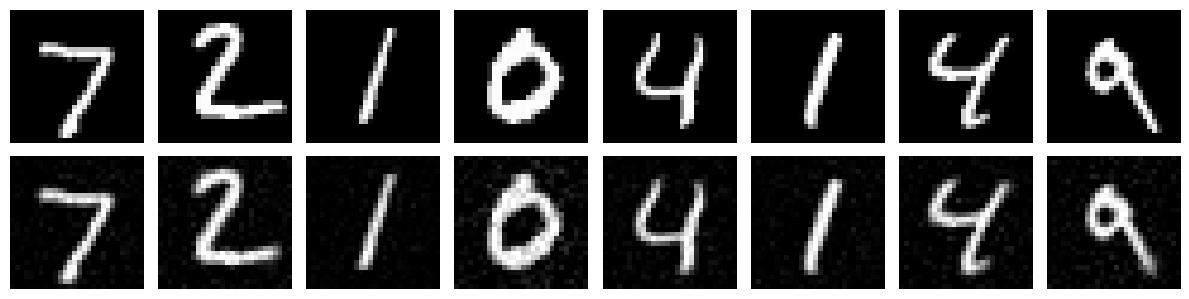

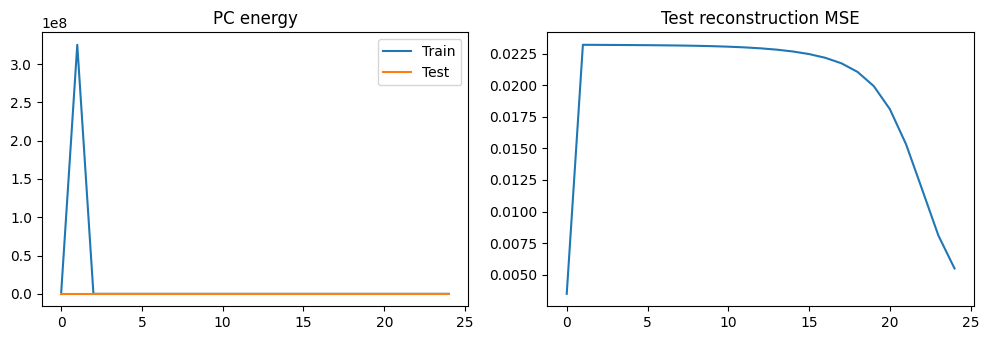

In [4]:
@torch.no_grad()
def show_examples(model, loader, count=8):
    images, _ = next(iter(loader))
    original = images[:count].to(DEVICE)
    reconstructed = model.infer(original.flatten(1))[0].reshape(-1, 28, 28)
    fig, axes = plt.subplots(2, count, figsize=(count*1.5, 3.2))
    for j in range(count):
        axes[0, j].imshow(original[j,0].cpu(), cmap='gray', vmin=0, vmax=1)
        axes[1, j].imshow(reconstructed[j].cpu().clamp(0,1), cmap='gray', vmin=0, vmax=1)
        axes[0, j].axis('off'); axes[1, j].axis('off')
    plt.tight_layout(); plt.show()
show_examples(model, test_loader)
fig, axs = plt.subplots(1,2,figsize=(10,3.5))
axs[0].plot(history['train_energy'],label='Train'); axs[0].plot(history['test_energy'],label='Test'); axs[0].legend(); axs[0].set_title('PC energy')
axs[1].plot(history['test_mse']); axs[1].set_title('Test reconstruction MSE')
plt.tight_layout(); plt.show()